# 14 - tabular foundation model: context optimization

frozen tfm (tabicl v2), so the context is the only thing to optimize. see `docs/tfm_context_plan.md`.

phase 1: setup and data. context pool = val split, scoring target = test split.

## 1 - imports and setup

In [1]:
%load_ext autoreload
%autoreload 2

import json
import os
import shutil
import sys
import time
from importlib.metadata import version

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import average_precision_score, roc_auc_score
from tabicl import TabICLClassifier

sys.path.insert(0, os.path.abspath('..'))

import config
from src.evaluation import evaluate_performance
from src.experiment import log_run
from src.tfm import (
    build_balanced_context,
    build_context_bank,
    correct_odds,
    describe_bank,
    fit_predict_stacked,
    fit_predict_tfm,
    load_cached_run,
    log_msg,
    memory_report,
    nan_flag_cols,
    prep_tfm,
    recall_at_alert,
    route_bank,
    save_run,
    score_with_bank,
)

cfg = config.TFM
print(cfg)

{'n_ctx': 10000, 'fraud_rate': 0.2, 'seeds': [0, 1, 2], 'alert_rates': [0.01, 0.2], 'tree_depth': 3, 'min_samples_leaf': 5000, 'min_leaf_fraud': 50, 'kv_cache': 'repr', 'force_rerun': False}


## 2 - environment check

In [2]:
print(f"torch {torch.__version__}  cuda build {torch.version.cuda}  cuda available {torch.cuda.is_available()}")
print(f"device: {torch.cuda.get_device_name(0)}")
print(f"vram: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} gb")
print(f"tabicl {version('tabicl')}")

torch 2.14.1+cu130  cuda build 13.0  cuda available True
device: NVIDIA GeForce RTX 3050 Ti Laptop GPU
vram: 4.0 gb
tabicl 2.2.0


## 3 - load val and test

In [3]:
X_val  = pd.read_parquet(config.RESULTS_PATH / 'X_val_selected.parquet')
X_test = pd.read_parquet(config.RESULTS_PATH / 'X_test_selected.parquet')
y_val  = pd.read_parquet(config.RESULTS_PATH / 'y_val.parquet').squeeze()
y_test = pd.read_parquet(config.RESULTS_PATH / 'y_test.parquet').squeeze()
feats_115 = X_val.columns

# has_identity is not in the 115 selected features, take it from the full splits for segment routing
X_val['has_identity']  = pd.read_parquet(config.RESULTS_PATH / 'X_val.parquet',  columns=['has_identity']).squeeze()
X_test['has_identity'] = pd.read_parquet(config.RESULTS_PATH / 'X_test.parquet', columns=['has_identity']).squeeze()

for name, X, y in [('val', X_val, y_val), ('test', X_test, y_test)]:
    print(f"{name:5s} rows {len(X):,}  cols {X.shape[1]}  fraud {int(y.sum()):,}  fraud rate {y.mean():.2%}  has_identity {X['has_identity'].mean():.2%}")

val   rows 88,581  cols 116  fraud 3,042  fraud rate 3.43%  has_identity 17.19%
test  rows 88,581  cols 116  fraud 3,083  fraud rate 3.48%  has_identity 20.53%


## 4 - prior_score from the stage 09 ensemble

blended probability before the 0-1000 rank transform. weights are val auc normalized, same as stage 09. no retraining.

In [4]:
models_dir  = config.OUTPUT_PATH / 'models'
cat_model   = joblib.load(models_dir / 'catboost_final.pkl')
xgb_model   = joblib.load(models_dir / 'xgboost_final.pkl')
lgb_booster = joblib.load(models_dir / 'lightgbm_final.pkl')

val_probas  = [cat_model.predict_proba(X_val[feats_115])[:, 1],  xgb_model.predict_proba(X_val[feats_115])[:, 1],  lgb_booster.predict(X_val[feats_115])]
test_probas = [cat_model.predict_proba(X_test[feats_115])[:, 1], xgb_model.predict_proba(X_test[feats_115])[:, 1], lgb_booster.predict(X_test[feats_115])]

raw_weights = np.array([roc_auc_score(y_val, p) for p in val_probas])
weights = raw_weights / raw_weights.sum()

X_val['prior_score']  = sum(w * p for w, p in zip(weights, val_probas))
X_test['prior_score'] = sum(w * p for w, p in zip(weights, test_probas))

# check against the weights logged and the scores saved in stage 09
log = json.load(open(config.RESULTS_PATH / 'experiment_log.json'))
logged_weights = [r for r in log if r['model'] == 'ensemble_weighted'][-1]['params']['weights']
saved_val  = pd.read_parquet(config.RESULTS_PATH / 'ensemble_val_proba.parquet').squeeze()
saved_test = pd.read_parquet(config.RESULTS_PATH / 'ensemble_test_proba.parquet').squeeze()

print(f"weights cat/xgb/lgb: {np.round(weights, 4)}  logged: {np.round(logged_weights, 4)}")
print(f"max abs diff vs saved  val {np.abs(X_val['prior_score'] - saved_val).max():.2e}  test {np.abs(X_test['prior_score'] - saved_test).max():.2e}")
print(f"prior_score auc  val {roc_auc_score(y_val, X_val['prior_score']):.5f}  test {roc_auc_score(y_test, X_test['prior_score']):.5f}")
del cat_model, xgb_model, lgb_booster, val_probas, test_probas, saved_val, saved_test

weights cat/xgb/lgb: [0.333  0.3348 0.3322]  logged: [0.333  0.3348 0.3322]
max abs diff vs saved  val 0.00e+00  test 0.00e+00
prior_score auc  val 0.92460  test 0.90546


## 5 - feature ranking

In [5]:
shap_imp = pd.read_parquet(config.RESULTS_PATH / 'shap_importance.parquet').sort_values('shap_importance', ascending=False)
ranking_source = 'stage 12 ensemble mean abs shap (shap_importance.parquet)'

tfm_feats   = shap_imp['feature'].head(25).tolist()
route_feats = shap_imp['feature'].head(5).tolist()

print(f"ranking: {ranking_source}")
print(f"route_feats (top 5): {route_feats}")
print(f"tfm_feats (top 25): {tfm_feats}")

ranking: stage 12 ensemble mean abs shap (shap_importance.parquet)
route_feats (top 5): ['C13', 'C1', 'D15', 'C5', 'TransactionAmt']
tfm_feats (top 25): ['C13', 'C1', 'D15', 'C5', 'TransactionAmt', 'card1__R_emaildomain__nunique', 'M4_encoded', 'P_emaildomain__TransactionAmt__mean', 'D1', 'card1__TransactionAmt__mean', 'D4', 'card1', 'M5_encoded', 'V69', 'card1__addr1__nunique_log', 'card6_encoded', 'M6_encoded', 'addr1__card1__nunique', 'card1__TransactionID__count', 'card2', 'V90', 'D10', 'card1__TransactionAmt__std', 'M3_encoded', 'DeviceInfo__P_emaildomain__nunique']


## 6 - nan handling

tabicl mean-imputes numeric nans with a SimpleImputer fit on the context and treats numeric columns as continuous.
label-encoded categoricals are int, so they pass through as numeric (same as the tree models saw them).
mean imputation drops the missingness signal, which is predictive here, so `prep_tfm` adds an `_isna` flag
for each tfm feature with more than 1% missing in the pool.

In [6]:
nan_check = pd.DataFrame({
    'nan_rate':     X_val[tfm_feats].isna().mean(),
    'fraud_if_nan': [y_val[X_val[c].isna()].mean() if X_val[c].isna().any() else np.nan for c in tfm_feats],
    'fraud_if_not': [y_val[X_val[c].notna()].mean() for c in tfm_feats],
}).query('nan_rate > 0').round(4)
display(nan_check)

flag_cols  = nan_flag_cols(X_val, tfm_feats)
model_cols = tfm_feats + ['prior_score']
print(f"nan flags for {len(flag_cols)} features: {flag_cols}")
print(f"tfm input width: {len(model_cols)} features + {len(flag_cols)} flags = {len(model_cols) + len(flag_cols)}")

,nan_rate,fraud_if_nan,fraud_if_not
D15,0.1369,0.0566,0.0308
P_emaildomain__TransactionAmt__mean,0.1595,0.0295,0.0353
D1,0.0108,0.0408,0.0343
D4,0.2780,0.0395,0.0324
V69,0.0766,0.0825,0.0303
addr1__card1__nunique,0.1005,0.1269,0.0240
card2,0.0090,0.0138,0.0345
V90,0.1371,0.0565,0.0308
D10,0.0855,0.0722,0.0308
card1__TransactionAmt__std,0.0048,0.0588,0.0342


nan flags for 9 features: ['D15', 'P_emaildomain__TransactionAmt__mean', 'D1', 'D4', 'V69', 'addr1__card1__nunique', 'V90', 'D10', 'DeviceInfo__P_emaildomain__nunique']
tfm input width: 26 features + 9 flags = 35


## 7 - timing check

random 10k val rows as context, predict 10k test rows. fit is preprocessing only, the forward pass happens in predict.
also runs a 5k context for comparison and as the fallback if 10k runs out of memory.
the auc on the 10k slice is a sanity check, not a result (random context at the natural 3.4% fraud rate).

In [7]:
rng = np.random.default_rng(0)
target_idx = rng.choice(len(X_test), 10000, replace=False)
X_tgt = prep_tfm(X_test.iloc[target_idx], model_cols, flag_cols)
y_tgt = y_test.iloc[target_idx]
prior_auc_slice = roc_auc_score(y_tgt, X_test['prior_score'].iloc[target_idx])

timing = []
for n in [cfg['n_ctx'], 5000]:
    ctx_idx = rng.choice(len(X_val), n, replace=False)
    X_ctx = prep_tfm(X_val.iloc[ctx_idx], model_cols, flag_cols)
    y_ctx = y_val.iloc[ctx_idx]
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    try:
        clf = TabICLClassifier(device='cuda', random_state=0)
        t0 = time.perf_counter()
        clf.fit(X_ctx, y_ctx)
        t1 = time.perf_counter()
        proba = clf.predict_proba(X_tgt)[:, 1]
        t2 = time.perf_counter()
        timing.append({
            'n_ctx': n, 'n_target': len(X_tgt), 'ctx_fraud': int(y_ctx.sum()),
            'fit_s': round(t1 - t0, 2), 'predict_s': round(t2 - t1, 2),
            'sec_per_100k': round((t2 - t0) / len(X_tgt) * 100000, 1),
            'peak_gpu_gb': round(torch.cuda.max_memory_allocated() / 1024**3, 2),
            'tfm_auc_slice': round(roc_auc_score(y_tgt, proba), 4),
            'prior_auc_slice': round(prior_auc_slice, 4),
            'status': 'ok',
        })
        del clf
    except torch.OutOfMemoryError as e:
        timing.append({'n_ctx': n, 'status': f'oom: {str(e)[:80]}'})

display(pd.DataFrame(timing))

,n_ctx,n_target,ctx_fraud,fit_s,predict_s,sec_per_100k,peak_gpu_gb,tfm_auc_slice,prior_auc_slice,status
0,10000,10000,349,1.30,11.79,130.9,3.09,0.9165,0.9036,ok
1,5000,10000,167,0.87,6.89,77.6,2.51,0.9164,0.9036,ok


## 8 - row counts and fraud rates

In [8]:
counts = pd.DataFrame({
    'rows':       [len(y_val), len(y_test)],
    'fraud':      [int(y_val.sum()), int(y_test.sum())],
    'fraud_rate': [round(y_val.mean(), 4), round(y_test.mean(), 4)],
}, index=['val (pool)', 'test (target)'])
display(counts)
assert len(y_val) == 88581 and len(y_test) == 88581

,rows,fraud,fraud_rate
val (pool),88581,3042,0.0343
test (target),88581,3083,0.0348


## 9 - runs A, C0 and C

- **A**: production ensemble `prior_score` alone on test. the bar to beat
- **C0**: tfm with a random 10k context from val (natural 3.4% fraud rate)
- **C**: tfm with one class-balanced global context from val at 20% fraud, odds corrected

every test row is scored against at most `n_ctx` context rows. `prior_score` is one of the tfm inputs.
a single global keep_rate is a monotonic transform, so it leaves C's ranking metrics unchanged; it matters once
leaves with different keep rates are pooled in run D.

In [9]:
label = config.TARGET
pool = X_val[model_cols].assign(**{label: y_val.values})
n_test = len(X_test)
scores_path = config.RESULTS_PATH / 'tfm_scores.parquet'
runs_path   = config.RESULTS_PATH / 'tfm_runs.parquet'
print(f"force_rerun {cfg['force_rerun']}  scores cache {scores_path.exists()}  timing cache {runs_path.exists()}")

per_seed = []

a_perf = evaluate_performance(X_test, 'prior_score', y_test.values)
per_seed.append({
    'run': 'A', 'seed': -1, 'pr_auc': a_perf['PR AUC'], 'roc_auc': a_perf['AUC'],
    **{f'recall_at_{r:.0%}': recall_at_alert(y_test, X_test['prior_score'], r) for r in cfg['alert_rates']},
    'fit_s': 0.0, 'predict_s': 0.0, 'ctx_rows': 0, 'ctx_fraud_rate': np.nan, 'keep_rate': np.nan,
})
save_run(scores_path, runs_path, 'A', -1, X_test['prior_score'].values, {'fit_s': 0.0, 'predict_s': 0.0})

runs_c = {'C0': None, 'C': cfg['fraud_rate']}
computed_runs = set()
for run, fraud_rate in runs_c.items():
    for seed in cfg['seeds']:
        t_seed = time.perf_counter()
        # context is cheap and deterministic so it is rebuilt even on a cache hit for the ctx stats
        ctx, keep_rate = build_balanced_context(pool, model_cols, label, n_ctx=cfg['n_ctx'], fraud_rate=fraud_rate, seed=seed)
        cached = None if cfg['force_rerun'] else load_cached_run(scores_path, runs_path, run, seed)
        if cached is not None:
            score, t = cached
            log_msg(f"{run} seed {seed}  loaded from cache")
        else:
            log_msg(f"{run} seed {seed}  start")
            raw, t = fit_predict_tfm(ctx, X_test, model_cols, label, flag_cols, seed=seed,
                                     kv_cache=cfg['kv_cache'], verbose=True)
            score = correct_odds(raw, keep_rate)
            save_run(scores_path, runs_path, run, seed, score, t)
            computed_runs.add(run)
            log_msg(f"{run} seed {seed}  end  {time.perf_counter() - t_seed:.1f}s elapsed")
        X_test['_score'] = score
        perf = evaluate_performance(X_test, '_score', y_test.values)
        per_seed.append({
            'run': run, 'seed': seed, 'pr_auc': perf['PR AUC'], 'roc_auc': perf['AUC'],
            **{f'recall_at_{r:.0%}': recall_at_alert(y_test, score, r) for r in cfg['alert_rates']},
            'fit_s': t['fit_s'], 'predict_s': t['predict_s'],
            'ctx_rows': len(ctx), 'ctx_fraud_rate': ctx[label].mean(), 'keep_rate': keep_rate,
        })
        print(f"{run} seed {seed}  pr_auc {perf['PR AUC']:.4f}  roc_auc {perf['AUC']:.4f}  fit {t['fit_s']:.1f}s  predict {t['predict_s']:.1f}s", flush=True)
    log_msg(f"{run} done  {memory_report()}")
X_test = X_test.drop(columns='_score')

force_rerun False  scores cache True  timing cache True


[2026-11-21 11:11:22] C0 seed 0  loaded from cache


C0 seed 0  pr_auc 0.5650  roc_auc 0.9208  fit 7.9s  predict 79.1s


[2026-11-21 11:11:22] C0 seed 1  loaded from cache


C0 seed 1  pr_auc 0.5752  roc_auc 0.9195  fit 5.1s  predict 75.8s


[2026-11-21 11:11:22] C0 seed 2  loaded from cache


... (5 outputs left out)

C seed 1  pr_auc 0.6266  roc_auc 0.9318  fit 7.8s  predict 78.6s


[2026-11-21 11:11:23] C seed 2  loaded from cache


C seed 2  pr_auc 0.6283  roc_auc 0.9317  fit 8.0s  predict 79.1s


[2026-11-21 11:11:23] C done  ram free 12.1 of 31.7 gb  gpu free 1.93 of 4.00 gb


## 9b - run S: stacked catboost on the val pool

control for the lift from fresh val labels. same 35 inputs as the tfm runs, trained on val instead of used as context.
val is in time order (stage 04 sorts by TransactionDT), so the first 80% fits and the last 20% is early stopping only.
scale_pos_weight for imbalance, fixed defaults, no tuning, random_seed 0.

In [10]:
t_seed = time.perf_counter()
cached = None if cfg['force_rerun'] else load_cached_run(scores_path, runs_path, 'S', 0)
if cached is not None:
    s_score, s_t = cached
    log_msg("S seed 0  loaded from cache")
else:
    log_msg("S seed 0  start")
    s_score, s_info = fit_predict_stacked(pool, X_test, model_cols, label, flag_cols, fit_frac=0.8, seed=0)
    s_t = {'fit_s': s_info['fit_s'], 'predict_s': s_info['predict_s']}
    save_run(scores_path, runs_path, 'S', 0, s_score, s_t)
    computed_runs.add('S')
    log_msg(f"S seed 0  end  {time.perf_counter() - t_seed:.1f}s elapsed  best iteration {s_info['best_iteration']}  "
            f"fit rows {s_info['fit_rows']:,}  early stopping rows {s_info['es_rows']:,}")

X_test['_score'] = s_score
perf = evaluate_performance(X_test, '_score', y_test.values)
X_test = X_test.drop(columns='_score')
per_seed.append({
    'run': 'S', 'seed': 0, 'pr_auc': perf['PR AUC'], 'roc_auc': perf['AUC'],
    **{f'recall_at_{r:.0%}': recall_at_alert(y_test, s_score, r) for r in cfg['alert_rates']},
    'fit_s': s_t['fit_s'], 'predict_s': s_t['predict_s'],
    'ctx_rows': len(pool), 'ctx_fraud_rate': y_val.mean(), 'keep_rate': np.nan,
})
print(f"S seed 0  pr_auc {perf['PR AUC']:.4f}  roc_auc {perf['AUC']:.4f}  fit {s_t['fit_s']:.1f}s  predict {s_t['predict_s']:.1f}s", flush=True)
log_msg(f"S done  {memory_report()}")

[2026-11-21 11:11:23] S seed 0  loaded from cache


S seed 0  pr_auc 0.5579  roc_auc 0.9192  fit 3.2s  predict 0.0s


[2026-11-21 11:11:23] S done  ram free 12.2 of 31.7 gb  gpu free 1.93 of 4.00 gb


## 9c - runs D and D_seg: routed context bank

- **D**: a depth 3 tree on the top 5 features splits the val pool into leaves. each leaf gets its own class-balanced
  context from its own rows only (its fraud plus negatives to 20%, capped at `n_ctx`), test rows are routed with
  `tree.apply` and odds corrected with their leaf's keep rate. leaves under `min_leaf_fraud` frauds use the global context
- **D_seg**: same bank, routed on the business segment `has_identity` instead of the tree
- **D_fill**: same tree as D, but each leaf context is filled with that leaf's own negatives up to `n_ctx` rows.
  the leaf fraud rate is whatever results and the per leaf keep rate still drives the odds correction.
  isolates context size from routing: D gives low-fraud leaves only 280 to 1,005 context rows

banks are cheap and deterministic so they are rebuilt every run; only the tfm scoring is cached.

In [11]:
# run -> (segment_col, fill_to_n_ctx)
bank_runs = {'D': (None, False), 'D_seg': ('has_identity', False), 'D_fill': (None, True)}
bank_pool = pool.assign(has_identity=X_val['has_identity'].values)
banks = {}
for run, (segment_col, fill) in bank_runs.items():
    for seed in cfg['seeds']:
        t_seed = time.perf_counter()
        bank = build_context_bank(
            bank_pool, route_feats, model_cols, label, max_depth=cfg['tree_depth'],
            min_samples_leaf=cfg['min_samples_leaf'], n_ctx=cfg['n_ctx'], fraud_rate=cfg['fraud_rate'],
            min_leaf_fraud=cfg['min_leaf_fraud'], seed=seed, segment_col=segment_col, fill_to_n_ctx=fill,
        )
        banks[(run, seed)] = bank
        cached = None if cfg['force_rerun'] else load_cached_run(scores_path, runs_path, run, seed)
        if cached is not None:
            score, t = cached
            log_msg(f"{run} seed {seed}  loaded from cache")
        else:
            log_msg(f"{run} seed {seed}  start  {len(bank['contexts'])} keys")
            score, t_full = score_with_bank(bank, X_test, model_cols, label, flag_cols, seed=seed,
                                            kv_cache=cfg['kv_cache'], verbose=True)
            t = {'fit_s': t_full['fit_s'], 'predict_s': t_full['predict_s']}
            save_run(scores_path, runs_path, run, seed, score, t)
            computed_runs.add(run)
            log_msg(f"{run} seed {seed}  end  {time.perf_counter() - t_seed:.1f}s elapsed")
        X_test['_score'] = score
        perf = evaluate_performance(X_test, '_score', y_test.values)
        X_test = X_test.drop(columns='_score')
        per_seed.append({
            'run': run, 'seed': seed, 'pr_auc': perf['PR AUC'], 'roc_auc': perf['AUC'],
            **{f'recall_at_{r:.0%}': recall_at_alert(y_test, score, r) for r in cfg['alert_rates']},
            'fit_s': t['fit_s'], 'predict_s': t['predict_s'],
            'ctx_rows': max(len(c) for c in bank['contexts'].values()),
            'ctx_fraud_rate': np.mean([c[label].mean() for c in bank['contexts'].values()]),
            'keep_rate': np.nan,
        })
        print(f"{run} seed {seed}  pr_auc {perf['PR AUC']:.4f}  roc_auc {perf['AUC']:.4f}  fit {t['fit_s']:.1f}s  predict {t['predict_s']:.1f}s", flush=True)
    log_msg(f"{run} done  {memory_report()}")

[2026-11-21 11:11:23] D seed 0  loaded from cache


D seed 0  pr_auc 0.6042  roc_auc 0.9273  fit 11.3s  predict 74.1s


[2026-11-21 11:11:24] D seed 1  loaded from cache


D seed 1  pr_auc 0.5990  roc_auc 0.9245  fit 12.1s  predict 75.1s


[2026-11-21 11:11:24] D seed 2  loaded from cache


D seed 2  pr_auc 0.6019  roc_auc 0.9268  fit 11.7s  predict 75.0s

... (11 outputs left out)

D_fill seed 1  pr_auc 0.6174  roc_auc 0.9284  fit 25.5s  predict 82.3s


[2026-11-21 11:11:25] D_fill seed 2  loaded from cache


D_fill seed 2  pr_auc 0.6217  roc_auc 0.9290  fit 22.9s  predict 78.7s


[2026-11-21 11:11:25] D_fill done  ram free 12.1 of 31.7 gb  gpu free 1.93 of 4.00 gb


In [12]:
# ctx_rows is the largest context a test row can see (each row sees at most n_ctx rows in every run)
per_seed = pd.DataFrame(per_seed)
per_seed['sec_per_100k'] = (per_seed['fit_s'] + per_seed['predict_s']) / n_test * 100000
display(per_seed.round(4))

,run,seed,pr_auc,roc_auc,recall_at_1%,recall_at_20%,fit_s,predict_s,ctx_rows,ctx_fraud_rate,keep_rate,sec_per_100k
0,A,-1,0.5194,0.9055,0.2543,0.8248,0.0000,0.0000,0,NaN,NaN,0.0000
1,C0,0,0.5650,0.9208,0.2491,0.8553,7.9035,79.1056,10000,0.0332,1.0000,98.2255
2,C0,1,0.5752,0.9196,0.2553,0.8498,5.0695,75.7649,10000,0.0332,1.0000,91.2548
3,C0,2,0.5702,0.9187,0.2566,0.8505,5.4778,75.5565,10000,0.0360,1.0000,91.4805
4,C,0,0.6249,0.9335,0.2634,0.8784,5.5416,77.2553,10000,0.2000,0.1423,93.4703
5,C,1,0.6266,0.9318,0.2618,0.8748,7.8472,78.5501,10000,0.2000,0.1423,97.5348
6,C,2,0.6283,0.9317,0.2666,0.8729,8.0434,79.1455,10000,0.2000,0.1423,98.4284
7,S,0,0.5579,0.9192,0.2462,0.8537,3.1611,0.0256,88581,0.0343,NaN,3.5975
8,D,0,0.6042,0.9273,0.2572,0.8699,11.3266,74.0816,7725,0.2000,NaN,96.4182
9,D,1,0.5990,0.9246,0.2595,0.8511,12.1089,75.0531,7725,0.2000,NaN,98.3980


## 10 - results table (mean and std over seeds)

In [13]:
metric_cols = ['pr_auc', 'roc_auc', 'recall_at_1%', 'recall_at_20%', 'fit_s', 'predict_s', 'sec_per_100k']
agg = per_seed.groupby('run', sort=False)[metric_cols].agg(['mean', 'std'])
results = pd.DataFrame({
    m: [f"{agg.loc[r, (m, 'mean')]:.4f} +- {0 if np.isnan(agg.loc[r, (m, 'std')]) else agg.loc[r, (m, 'std')]:.4f}" if m in metric_cols[:4]
        else f"{agg.loc[r, (m, 'mean')]:.1f}" for r in agg.index]
    for m in metric_cols
}, index=agg.index)
results.insert(0, 'ctx_fraud_rate', per_seed.groupby('run', sort=False)['ctx_fraud_rate'].mean().round(3))
display(results)

,ctx_fraud_rate,pr_auc,roc_auc,recall_at_1%,recall_at_20%,fit_s,predict_s,sec_per_100k
run,,,,,,,,
A,NaN,0.5194 +- 0.0000,0.9055 +- 0.0000,0.2543 +- 0.0000,0.8248 +- 0.0000,0.0,0.0,0.0
C0,0.034,0.5701 +- 0.0051,0.9197 +- 0.0011,0.2536 +- 0.0040,0.8519 +- 0.0030,6.2,76.8,93.7
C,0.200,0.6266 +- 0.0017,0.9323 +- 0.0010,0.2639 +- 0.0025,0.8753 +- 0.0028,7.1,78.3,96.5
S,0.034,0.5579 +- 0.0000,0.9192 +- 0.0000,0.2462 +- 0.0000,0.8537 +- 0.0000,3.2,0.0,3.6
D,0.200,0.6017 +- 0.0026,0.9262 +- 0.0015,0.2580 +- 0.0013,0.8625 +- 0.0100,11.7,74.7,97.6
D_seg,0.200,0.6259 +- 0.0010,0.9346 +- 0.0004,0.2615 +- 0.0013,0.8786 +- 0.0010,6.3,64.0,79.4
D_fill,0.058,0.6202 +- 0.0024,0.9297 +- 0.0018,0.2604 +- 0.0005,0.8673 +- 0.0096,24.6,80.1,118.2


## 10b - bank description and per key C vs D

one row per routing key (routing is identical across seeds, checked below). pool and context stats are from the
seed 0 bank. pr-auc is computed on that key's test rows only, mean over seeds; `d_minus_c` > 0 means routing helped
that region. per key pr-auc is within-key ranking only; the pooled table above is what the odds correction affects.

In [14]:
all_scores = pd.read_parquet(scores_path).sort_values(['run', 'seed', 'row'])
score_of = {(r, s): g['score'].to_numpy() for (r, s), g in all_scores.groupby(['run', 'seed'])}
yt = y_test.to_numpy()

pd.set_option('display.max_colwidth', 80)
key_tables = {}
for run in bank_runs:
    keys = route_bank(banks[(run, cfg['seeds'][0])], X_test)
    assert all((route_bank(banks[(run, s)], X_test) == keys).all() for s in cfg['seeds'])
    desc = describe_bank(banks[(run, cfg['seeds'][0])], route_feats)
    desc['test_rows'] = [int((keys == k).sum()) for k in desc.index]
    desc['test_fraud_rate'] = [yt[keys == k].mean() for k in desc.index]
    for r in ['A', 'C', run]:
        seeds = [-1] if r == 'A' else cfg['seeds']
        desc[f'pr_auc_{r}'] = [
            np.mean([average_precision_score(yt[keys == k], score_of[(r, s)][keys == k]) for s in seeds])
            if yt[keys == k].sum() > 0 else np.nan
            for k in desc.index
        ]
    desc['d_minus_c'] = desc[f'pr_auc_{run}'] - desc['pr_auc_C']
    key_tables[run] = desc
    if run != 'D_fill':
        print(f"\n{run}: {len(desc)} keys  test rows covered {desc['test_rows'].sum():,}")
        display(desc.round(4))

# D vs D_fill per leaf: same tree, only the context size and fraud rate differ
assert (key_tables['D'].index == key_tables['D_fill'].index).all()
d, f = key_tables['D'], key_tables['D_fill']
leaf_cmp = pd.DataFrame({
    'rule': d['rule'], 'test_rows': d['test_rows'], 'test_fraud_rate': d['test_fraud_rate'],
    'ctx_rows_D': d['ctx_rows'], 'ctx_fraud_rate_D': d['ctx_fraud_rate'],
    'ctx_rows_D_fill': f['ctx_rows'], 'ctx_fraud_rate_D_fill': f['ctx_fraud_rate'],
    'pr_auc_C': d['pr_auc_C'], 'pr_auc_D': d['pr_auc_D'], 'pr_auc_D_fill': f['pr_auc_D_fill'],
    'd_minus_c': d['d_minus_c'], 'd_fill_minus_c': f['d_minus_c'],
})
print("\nD vs D_fill per leaf")
display(leaf_cmp.round(4))


D: 7 keys  test rows covered 88,581


,rule,pool_rows,pool_fraud_rate,ctx_rows,ctx_fraud_rate,keep_rate,fallback,test_rows,test_fraud_rate,pr_auc_A,pr_auc_C,pr_auc_D,d_minus_c
key,,,,,,,,,,,,,
3,C5 <= 0.5 and C1 <= 3.5 and (D15 <= 101.5 or nan),33471,0.0462,7725,0.2,0.1936,no,33855,0.0429,0.3513,0.3938,0.4101,0.0163
4,C5 <= 0.5 and C1 <= 3.5 and D15 > 101.5,13110,0.0153,1005,0.2,0.0623,no,14410,0.0193,0.3228,0.7190,0.6440,-0.0750
5,C5 <= 0.5 and C1 > 3.5,5058,0.1766,4465,0.2,0.8576,no,6671,0.1557,0.8419,0.8824,0.8530,-0.0294
8,C5 > 0.5 and TransactionAmt <= 108.8 and (D15 <= 96.5 or nan),11850,0.0113,670,0.2,0.0457,no,9727,0.0109,0.1178,0.2840,0.2411,-0.0429
9,C5 > 0.5 and TransactionAmt <= 108.8 and D15 > 96.5,14476,0.0055,395,0.2,0.0219,no,14214,0.0050,0.3739,0.5851,0.4578,-0.1273
11,C5 > 0.5 and TransactionAmt > 108.8 and (D15 <= 101.5 or nan),5596,0.0239,670,0.2,0.0981,no,5037,0.0167,0.0743,0.3102,0.3128,0.0027
12,C5 > 0.5 and TransactionAmt > 108.8 and D15 > 101.5,5020,0.0112,280,0.2,0.0451,no,4667,0.0111,0.7601,0.8451,0.7966,-0.0485



D_seg: 2 keys  test rows covered 88,581


,rule,pool_rows,pool_fraud_rate,ctx_rows,ctx_fraud_rate,keep_rate,fallback,test_rows,test_fraud_rate,pr_auc_A,pr_auc_C,pr_auc_D_seg,d_minus_c
key,,,,,,,,,,,,,
0,has_identity == 0,73350,0.0212,7765,0.2,0.0865,no,70399,0.0193,0.1913,0.4601,0.4772,0.0171
1,has_identity == 1,15231,0.0978,7445,0.2,0.4334,no,18182,0.0950,0.7261,0.7392,0.7262,-0.0130



D vs D_fill per leaf

,rule,test_rows,test_fraud_rate,ctx_rows_D,ctx_fraud_rate_D,ctx_rows_D_fill,ctx_fraud_rate_D_fill,pr_auc_C,pr_auc_D,pr_auc_D_fill,d_minus_c,d_fill_minus_c
key,,,,,,,,,,,,
3,C5 <= 0.5 and C1 <= 3.5 and (D15 <= 101.5 or nan),33855,0.0429,7725,0.2,10000,0.1545,0.3938,0.4101,0.4135,0.0163,0.0197
4,C5 <= 0.5 and C1 <= 3.5 and D15 > 101.5,14410,0.0193,1005,0.2,10000,0.0201,0.7190,0.6440,0.6924,-0.0750,-0.0266
5,C5 <= 0.5 and C1 > 3.5,6671,0.1557,4465,0.2,5058,0.1766,0.8824,0.8530,0.8534,-0.0294,-0.0290
8,C5 > 0.5 and TransactionAmt <= 108.8 and (D15 <= 96.5 or nan),9727,0.0109,670,0.2,10000,0.0134,0.2840,0.2411,0.3670,-0.0429,0.0830
9,C5 > 0.5 and TransactionAmt <= 108.8 and D15 > 96.5,14214,0.0050,395,0.2,10000,0.0079,0.5851,0.4578,0.5631,-0.1273,-0.0219
11,C5 > 0.5 and TransactionAmt > 108.8 and (D15 <= 101.5 or nan),5037,0.0167,670,0.2,5596,0.0239,0.3102,0.3128,0.3425,0.0027,0.0323
12,C5 > 0.5 and TransactionAmt > 108.8 and D15 > 101.5,4667,0.0111,280,0.2,5020,0.0112,0.8451,0.7966,0.8962,-0.0485,0.0511


## 11 - save per row scores and log runs

In [15]:
tfm_scores = pd.read_parquet(scores_path)
print(f"tfm_scores.parquet  {tfm_scores.shape}  runs {tfm_scores['run'].unique().tolist()}")

# val is the context pool so there is no val auc; val_auc is nan and all metrics are on test
# only runs recomputed in this session are logged so a cached rerun adds no duplicate entries
tfm_params = {'model': f"tabicl {version('tabicl')}", 'n_ctx': cfg['n_ctx'], 'seeds': cfg['seeds'],
              'kv_cache': cfg['kv_cache'], 'n_inputs': len(model_cols) + len(flag_cols)}
run_params = {
    'A':  {'model': 'ensemble_prior_score'},
    'C0': {**tfm_params, 'fraud_rate': None},
    'C':  {**tfm_params, 'fraud_rate': cfg['fraud_rate']},
    'S':  {'model': 'catboost stacked on val', 'n_inputs': len(model_cols) + len(flag_cols), 'fit_frac': 0.8,
           'iterations': 2000, 'learning_rate': 0.05, 'depth': 6, 'early_stopping_rounds': 100, 'random_seed': 0},
    'D':  {**tfm_params, 'fraud_rate': cfg['fraud_rate'], 'routing': 'tree', 'route_feats': route_feats,
           'tree_depth': cfg['tree_depth'], 'min_samples_leaf': cfg['min_samples_leaf'],
           'min_leaf_fraud': cfg['min_leaf_fraud'], 'n_keys': len(key_tables['D'])},
    'D_fill': {**tfm_params, 'fraud_rate_cap': cfg['fraud_rate'], 'fill_to_n_ctx': True, 'routing': 'tree',
               'route_feats': route_feats, 'tree_depth': cfg['tree_depth'], 'min_samples_leaf': cfg['min_samples_leaf'],
               'min_leaf_fraud': cfg['min_leaf_fraud'], 'n_keys': len(key_tables['D_fill'])},
    'D_seg': {**tfm_params, 'fraud_rate': cfg['fraud_rate'], 'routing': 'segment has_identity',
              'min_leaf_fraud': cfg['min_leaf_fraud'], 'n_keys': len(key_tables['D_seg'])},
}
for run in [r for r in agg.index if r in computed_runs]:
    log_run(
        model_name=f'tfm_{run}',
        params={'stage': 14, **run_params[run], 'context_pool': 'val', 'eval': 'test'},
        metrics={'val_auc': float('nan'),
                 **{f'test_{m}': round(float(agg.loc[run, (m, 'mean')]), 5) for m in metric_cols},
                 **{f'test_{m}_std': round(float(np.nan_to_num(agg.loc[run, (m, 'std')])), 5) for m in metric_cols[:4]}},
        results_path=config.RESULTS_PATH,
    )

tfm_scores.parquet  (1505877, 4)  runs ['C0', 'C', 'S', 'D', 'D_seg', 'D_fill', 'A']


## 12 - figure: recall vs alert rate

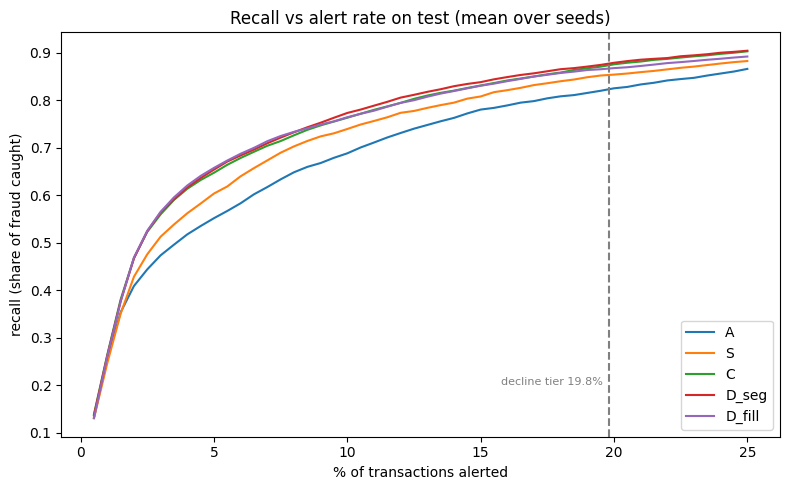

In [16]:
rates = np.linspace(0.005, 0.25, 50)
curve_runs = ['A', 'S', 'C', 'D_seg', 'D_fill']
seeds_of = all_scores.groupby('run')['seed'].unique()

fig, ax = plt.subplots(figsize=(8, 5))
for run in curve_runs:
    curves = np.array([[recall_at_alert(yt, score_of[(run, s)], r) for r in rates] for s in seeds_of[run]])
    ax.plot(rates * 100, curves.mean(axis=0), label=run)
ax.axvline(19.8, linestyle='--', color='grey')
ax.text(19.6, 0.2, 'decline tier 19.8%', color='grey', fontsize=8, ha='right')
ax.set_xlabel('% of transactions alerted')
ax.set_ylabel('recall (share of fraud caught)')
ax.set_title('Recall vs alert rate on test (mean over seeds)')
ax.legend(loc='lower right')
fig.tight_layout()
recall_path = config.PLOTS_PATH / 'tfm_recall_vs_alert.png'
fig.savefig(recall_path, dpi=150, bbox_inches='tight')
plt.show()
plt.close()

## 13 - figure: quality vs cost

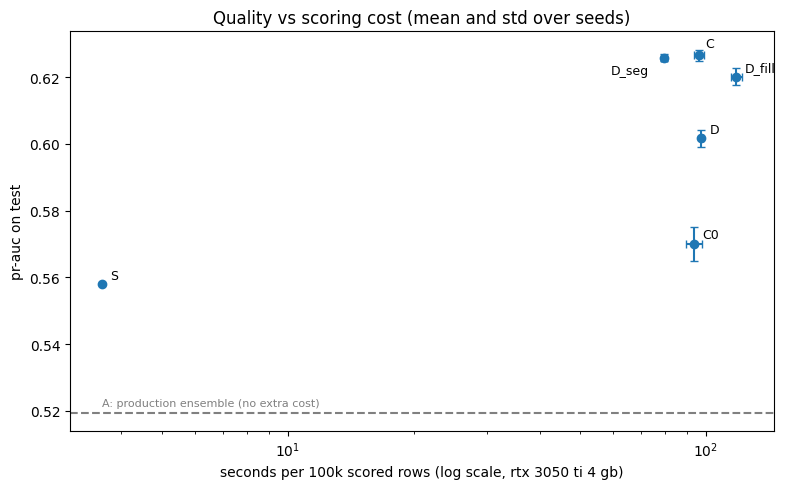

copied tfm_recall_vs_alert.png and tfm_pr_auc_vs_cost.png to assets


In [17]:
cost = per_seed.groupby('run', sort=False).agg(
    pr_auc=('pr_auc', 'mean'), pr_auc_std=('pr_auc', 'std'),
    sec=('sec_per_100k', 'mean'), sec_std=('sec_per_100k', 'std'),
).fillna(0)

fig, ax = plt.subplots(figsize=(8, 5))
pts = cost.drop(index='A')
ax.errorbar(pts['sec'], pts['pr_auc'], xerr=pts['sec_std'], yerr=pts['pr_auc_std'], fmt='o', capsize=3)
offsets = {'D_seg': (-38, -12), 'C': (4, 6)}
for run, row in pts.iterrows():
    ax.annotate(run, (row['sec'], row['pr_auc']), textcoords='offset points', xytext=offsets.get(run, (6, 4)), fontsize=9)
ax.axhline(cost.loc['A', 'pr_auc'], linestyle='--', color='grey')
ax.text(pts['sec'].min(), cost.loc['A', 'pr_auc'] + 0.002, 'A: production ensemble (no extra cost)', color='grey', fontsize=8)
ax.set_xscale('log')
ax.set_xlabel('seconds per 100k scored rows (log scale, rtx 3050 ti 4 gb)')
ax.set_ylabel('pr-auc on test')
ax.set_title('Quality vs scoring cost (mean and std over seeds)')
fig.tight_layout()
cost_path = config.PLOTS_PATH / 'tfm_pr_auc_vs_cost.png'
fig.savefig(cost_path, dpi=150, bbox_inches='tight')
plt.show()
plt.close()

assets_path = config.ROOT / 'assets'
for p in [recall_path, cost_path]:
    shutil.copy(p, assets_path / p.name)
print(f"copied {recall_path.name} and {cost_path.name} to assets")

## 14 - final tables

In [18]:
display(results)
display(leaf_cmp.round(4))

,ctx_fraud_rate,pr_auc,roc_auc,recall_at_1%,recall_at_20%,fit_s,predict_s,sec_per_100k
run,,,,,,,,
A,NaN,0.5194 +- 0.0000,0.9055 +- 0.0000,0.2543 +- 0.0000,0.8248 +- 0.0000,0.0,0.0,0.0
C0,0.034,0.5701 +- 0.0051,0.9197 +- 0.0011,0.2536 +- 0.0040,0.8519 +- 0.0030,6.2,76.8,93.7
C,0.200,0.6266 +- 0.0017,0.9323 +- 0.0010,0.2639 +- 0.0025,0.8753 +- 0.0028,7.1,78.3,96.5
S,0.034,0.5579 +- 0.0000,0.9192 +- 0.0000,0.2462 +- 0.0000,0.8537 +- 0.0000,3.2,0.0,3.6
D,0.200,0.6017 +- 0.0026,0.9262 +- 0.0015,0.2580 +- 0.0013,0.8625 +- 0.0100,11.7,74.7,97.6
D_seg,0.200,0.6259 +- 0.0010,0.9346 +- 0.0004,0.2615 +- 0.0013,0.8786 +- 0.0010,6.3,64.0,79.4
D_fill,0.058,0.6202 +- 0.0024,0.9297 +- 0.0018,0.2604 +- 0.0005,0.8673 +- 0.0096,24.6,80.1,118.2


,rule,test_rows,test_fraud_rate,ctx_rows_D,ctx_fraud_rate_D,ctx_rows_D_fill,ctx_fraud_rate_D_fill,pr_auc_C,pr_auc_D,pr_auc_D_fill,d_minus_c,d_fill_minus_c
key,,,,,,,,,,,,
3,C5 <= 0.5 and C1 <= 3.5 and (D15 <= 101.5 or nan),33855,0.0429,7725,0.2,10000,0.1545,0.3938,0.4101,0.4135,0.0163,0.0197
4,C5 <= 0.5 and C1 <= 3.5 and D15 > 101.5,14410,0.0193,1005,0.2,10000,0.0201,0.7190,0.6440,0.6924,-0.0750,-0.0266
5,C5 <= 0.5 and C1 > 3.5,6671,0.1557,4465,0.2,5058,0.1766,0.8824,0.8530,0.8534,-0.0294,-0.0290
8,C5 > 0.5 and TransactionAmt <= 108.8 and (D15 <= 96.5 or nan),9727,0.0109,670,0.2,10000,0.0134,0.2840,0.2411,0.3670,-0.0429,0.0830
9,C5 > 0.5 and TransactionAmt <= 108.8 and D15 > 96.5,14214,0.0050,395,0.2,10000,0.0079,0.5851,0.4578,0.5631,-0.1273,-0.0219
11,C5 > 0.5 and TransactionAmt > 108.8 and (D15 <= 101.5 or nan),5037,0.0167,670,0.2,5596,0.0239,0.3102,0.3128,0.3425,0.0027,0.0323
12,C5 > 0.5 and TransactionAmt > 108.8 and D15 > 101.5,4667,0.0111,280,0.2,5020,0.0112,0.8451,0.7966,0.8962,-0.0485,0.0511


## 15 - findings

1. the tfm beats the production ensemble. one class-balanced 10k context (C) lifts test pr-auc from 0.519 to 0.627
   and roc-auc from 0.906 to 0.932. catboost retrained on the same val rows and inputs (S) reaches 0.558, so fresh
   labels explain about a third of the lift and the tfm the rest
2. balancing the context matters. a random 10k context (C0, ~340 frauds) gets 0.570, the balanced one 0.627
3. tree routing does not help at this data scale. D (0.602) loses because low-fraud leaves get contexts of only
   280 to 1,005 rows. filling them to 10k rows (D_fill) recovers most of the gap (0.620) and wins 4 of 7 leaves,
   but low-fraud leaves still have few frauds to show and pooled D_fill stays below C.
   routing on has_identity (D_seg, 0.626) ties C
4. cost: C runs at ~96 s per 100k rows, D_seg ~79 s (about 18% cheaper for the same quality), D_fill ~118 s.
   catboost S scores at ~3.6 s, about 27x cheaper than C
5. caveats: val scores are mildly optimistic because val was used for early stopping and blend weights. S is untuned.
   timings are batch throughput on a 4 gb laptop gpu, not production latency